# **Assignment 11**

---

## **Import External Libraries**

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

from IPython.display import display, Math

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import UGate, CUGate, HGate, ZGate, QFTGate
from qiskit.quantum_info import Operator, Statevector
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh

In [2]:
# --- Shared helpers: qubit order |q_{n-1} ... q_1 q_0>, MSB = first tensor factor (IBM-Q convention) ---
def ket(bits):
    """Basis column vector |bits>, e.g. ket("01") = (0, 1, 0, 0)."""
    v = np.zeros(2 ** len(bits), dtype=complex)
    v[int(bits, 2)] = 1
    return v


def kron(*ms):
    out = np.array([[1.0 + 0j]])
    for m in ms:
        out = np.kron(out, m)
    return out


I2 = np.eye(2)
Z  = np.array([[1, 0], [0, -1]], dtype=complex)
H  = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
P0 = np.array([[1, 0], [0, 0]])   # |0><0|
P1 = np.array([[0, 0], [0, 1]])   # |1><1|

# U_{theta, phi, lambda, gamma} (lecture / IBM-Q definition), symbolic
th, ph, lam, gam = sp.symbols("theta phi lambda gamma", real=True)


def U4s(t, p, l, g):
    return sp.exp(sp.I * g) * sp.Matrix([[sp.cos(t / 2), -sp.exp(sp.I * l) * sp.sin(t / 2)],
                                         [sp.exp(sp.I * p) * sp.sin(t / 2), sp.exp(sp.I * (l + p)) * sp.cos(t / 2)]])


def qft_matrix(N):
    """U_QFT (course convention):  (U)_{kj} = omega^{-kj} / sqrt(N),  omega = e^{i 2 pi / N}."""
    k, j = np.meshgrid(np.arange(N), np.arange(N), indexing="ij")
    return np.exp(-2j * np.pi * k * j / N) / np.sqrt(N)


def qft_circuit(n, name="QFT"):
    """The lecture's n-qubit U_QFT circuit (Assignment 10): H and U_{CPS, -2 pi / 2^j}, then swaps. MSB = q_{n-1}."""
    qc = QuantumCircuit(n, name=name)
    for t in range(n - 1, -1, -1):
        qc.h(t)
        for j, c in enumerate(range(t - 1, -1, -1), start=2):
            qc.cp(-2 * np.pi / 2 ** j, c, t)
    for a in range(n // 2):
        qc.swap(a, n - 1 - a)
    return qc


# Simulators: ideal, and with the noise model of IBM's ibm_marrakesh (a snapshot of its calibration)
SHOTS   = 1024
SEED    = 2110515
ideal   = AerSimulator(seed_simulator=SEED)
noisy   = AerSimulator.from_backend(FakeMarrakesh(), seed_simulator=SEED)


def run(qc, sim):
    tqc = transpile(qc, sim, optimization_level=1, seed_transpiler=SEED)
    return sim.run(tqc, shots=SHOTS).result().get_counts()


def histograms(panels, filename, nbits, ncols=None, keys=None):
    """One horizontal histogram per panel; each panel = (title, ideal counts, noisy counts)."""
    ncols = ncols or len(panels)
    nrows = -(-len(panels) // ncols)
    keys = keys or [format(k, f"0{nbits}b") for k in range(2 ** nbits)]
    keys = keys[::-1]
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 0.8 + 0.3 * len(keys) * nrows), squeeze=False)
    y = np.arange(len(keys))
    for ax, (title, ci, cn) in zip(axes.flat, panels):
        ax.barh(y + 0.2, [ci.get(k, 0) for k in keys], height=0.4, color="#6fa8dc", label="ideal")
        ax.barh(y - 0.2, [cn.get(k, 0) for k in keys], height=0.4, color="#e69138", label="noisy (ibm_marrakesh)")
        ax.set_yticks(y, keys)
        ax.set_xlim(0, SHOTS)
        ax.set_xlabel("Frequency")
        ax.set_ylabel("Measurement outcome")
        ax.set_title(title)
        ax.grid(axis="x", alpha=0.4)
    fig.tight_layout()
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, 0.0))
    fig.savefig(f"../images/{filename}", dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def save_circuit(qc, filename, **kw):
    fig = qc.draw("mpl", **kw)
    fig.savefig(f"../images/{filename}", dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def qpe_circuit(n, eigvec_bits, z_power=lambda m: 2 ** m, simplify=True, measure_b=False):
    """QPE of the Z gate.  q0 = b-register, q1 ... qn = c-register (q_{m+1} has weight 2^m, q_n = MSB).
    Controlled-U^{2^m} = controlled-U_{0, 0, 2^m pi, 0} (Z^{2^m} = U_{0,0,2^m pi}).  With simplify=True the
    controlled gates that equal the identity (Z^{2^m} = I for m >= 1) are dropped."""
    qc = QuantumCircuit(QuantumRegister(n + 1, "q"), ClassicalRegister(n + 1, "c"))
    if eigvec_bits == "1":
        qc.x(0)                                    # |e_1> = |1>
    for m in range(n):
        qc.h(m + 1)
    qc.barrier()
    for m in range(n):
        p = z_power(m)
        if simplify and p % 2 == 0:
            continue                               # Z^{even} = I  ->  controlled-I = I
        qc.cu(0, 0, p * np.pi, 0, m + 1, 0)        # (theta, phi, lambda, gamma, control, target)
    qc.barrier()
    qc.compose(qft_circuit(n), qubits=list(range(1, n + 1)), inplace=True)
    qc.barrier()
    qc.measure(list(range(1, n + 1)), list(range(1, n + 1)))
    if measure_b:
        qc.measure(0, 0)
    return qc


---

## **1. Unitary Gate Construction**

In [3]:
# --- Problem 1: (1/sqrt2)[[-i, -i], [-i, i]] = U_{pi/2, 0, pi, -pi/2} = e^{-i pi/2} H ---
G = sp.Matrix([[-sp.I, -sp.I], [-sp.I, sp.I]]) / sp.sqrt(2)
display(Math(r"U_{\theta,\phi,\lambda,\gamma} = " + sp.latex(U4s(th, ph, lam, gam))))
sol = U4s(sp.pi / 2, 0, sp.pi, -sp.pi / 2)
display(Math(r"U_{\frac{\pi}{2},0,\pi,-\frac{\pi}{2}} = " + sp.latex(sp.simplify(sol))))
print("Problem 1  --  U_{pi/2, 0, pi, -pi/2} == given gate ?", sp.simplify(sol - G) == sp.zeros(2))
print("Problem 1  --  given gate == -i H ?", sp.simplify(G - (-sp.I) * sp.Matrix([[1, 1], [1, -1]]) / sp.sqrt(2)) == sp.zeros(2))
print("Problem 1  --  gamma = 3pi/2 gives the same matrix ?", sp.simplify(U4s(sp.pi / 2, 0, sp.pi, 3 * sp.pi / 2) - G) == sp.zeros(2))
Gn = np.array(G, dtype=complex)
print("Problem 1  --  Qiskit: exp(i gamma) UGate(pi/2, 0, pi) == given gate ?",
      np.allclose(np.exp(-1j * np.pi / 2) * Operator(UGate(np.pi / 2, 0, np.pi)).data, Gn),
      ",  unitary ?", np.allclose(Gn.conj().T @ Gn, np.eye(2)))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 1  --  U_{pi/2, 0, pi, -pi/2} == given gate ? True
Problem 1  --  given gate == -i H ? True
Problem 1  --  gamma = 3pi/2 gives the same matrix ? True
Problem 1  --  Qiskit: exp(i gamma) UGate(pi/2, 0, pi) == given gate ? True ,  unitary ? True


---

## **2. General Controlled Unitary Gate**

In [4]:
# --- Problem 2: e_{r,c} = <r| C-U |c>, with C-U|0x> = |0x>,  C-U|1x> = |1> U|x>  (control = MSB) ---
U = U4s(th, ph, lam, gam)
k0, k1 = sp.Matrix([1, 0]), sp.Matrix([0, 1])
kets = {"00": sp.kronecker_product(k0, k0), "01": sp.kronecker_product(k0, k1),
        "10": sp.kronecker_product(k1, k0), "11": sp.kronecker_product(k1, k1)}


def CU_on(bits):
    """Action of C-U on a basis ket, built from its definition (not from the matrix)."""
    c, t = bits
    tgt = k0 if t == "0" else k1
    return sp.kronecker_product(k0, tgt) if c == "0" else sp.kronecker_product(k1, U * tgt)


E = sp.Matrix(4, 4, lambda r, c: (kets[format(int(r), "02b")].T * CU_on(format(int(c), "02b")))[0])
for r, c in ((2, 2), (2, 3), (3, 2), (3, 3)):
    display(Math(rf"e_{{{r},{c}}} = \bra{{{format(r, '02b')}}} C\text{{-}}U \ket{{{format(c, '02b')}}} = " + sp.latex(sp.simplify(E[r, c]))))
eq1 = sp.Matrix([[1, 0, 0, 0], [0, 1, 0, 0],
                 [0, 0, sp.exp(sp.I * gam) * sp.cos(th / 2), -sp.exp(sp.I * (lam + gam)) * sp.sin(th / 2)],
                 [0, 0, sp.exp(sp.I * (ph + gam)) * sp.sin(th / 2), sp.exp(sp.I * (lam + ph + gam)) * sp.cos(th / 2)]])
print("Problem 2  --  all 16 elements <r|C-U|c> == Eq.(1) ?", sp.simplify(E - eq1) == sp.zeros(4))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 2  --  all 16 elements <r|C-U|c> == Eq.(1) ? True


---

## **3. General Controlled Unitary Gate Matrix**

In [5]:
# --- Problem 3: |0><0| (x) I + |1><1| (x) U == Eq.(1) ---
P0s, P1s = sp.Matrix([[1, 0], [0, 0]]), sp.Matrix([[0, 0], [0, 1]])
A, B = sp.kronecker_product(P0s, sp.eye(2)), sp.kronecker_product(P1s, U)
display(Math(r"\ket{0}\bra{0} \otimes I = " + sp.latex(A)))
display(Math(r"\ket{1}\bra{1} \otimes U = " + sp.latex(sp.simplify(B))))
print("Problem 3  --  sum == Eq.(1) ?", sp.simplify(A + B - eq1) == sp.zeros(4))
rng = np.random.default_rng(SEED)
ok = True
for _ in range(20):
    t, p, l, g = rng.uniform(0, 2 * np.pi, 4)
    Un = np.exp(1j * g) * Operator(UGate(t, p, l)).data
    ours = kron(P0, I2) + kron(P1, Un)
    ok &= np.allclose(ours, np.array(eq1.subs({th: t, ph: p, lam: l, gam: g}), dtype=complex))
    # Qiskit's CUGate uses control = q0 (LSB): the same gate with the qubit order swapped
    ok &= np.allclose(Operator(CUGate(t, p, l, g)).data, kron(I2, P0) + kron(Un, P1))
print("Problem 3  --  20 random (theta, phi, lambda, gamma): Eq.(2) == Eq.(1) == Qiskit CUGate ?", bool(ok))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 3  --  sum == Eq.(1) ? True


Problem 3  --  20 random (theta, phi, lambda, gamma): Eq.(2) == Eq.(1) == Qiskit CUGate ? True


---

## **4. QPE Calculation**

Z |e_0> = |0>: eigenvalue 1  ->  psi = 0.0
   c-register after kickback : [1. 1. 1. 1.] / 2
   after U_QFT               : [1.+0.j 0.+0.j 0.+0.j 0.+0.j]  -> |00>
Z |e_1> = |1> (text): eigenvalue -1  ->  psi = 0.5
   c-register after kickback : [ 1. -1.  1. -1.] / 2
   after U_QFT               : [0.+0.j 0.+0.j 1.+0.j 0.+0.j]  -> |10>
Statevector, b = |0>: {'000': 1.0}   (string q2 q1 q0 = c1 c0 b)


   ideal {'000': 1024}   noisy {'000': 1008, '010': 5, '100': 10, '110': 1}
Statevector, b = |1>: {'101': 1.0}   (string q2 q1 q0 = c1 c0 b)


   ideal {'100': 1024}   noisy {'000': 9, '010': 4, '100': 1009, '110': 2}


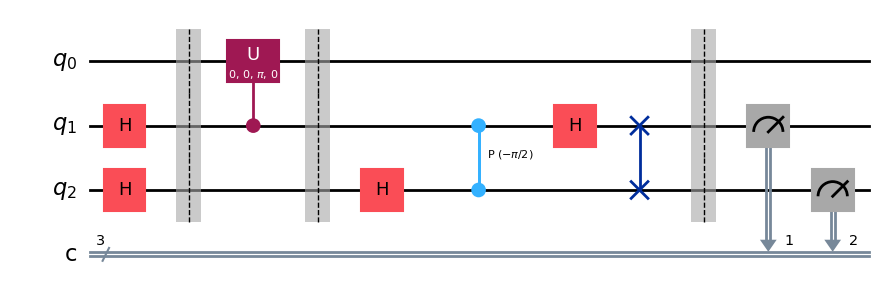

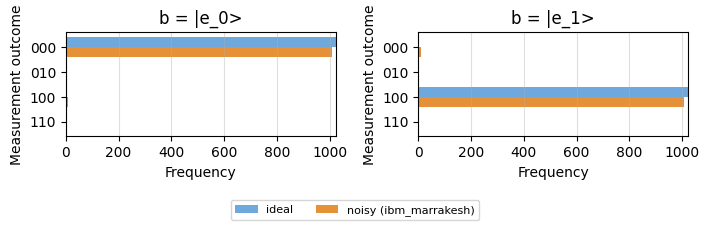

In [6]:
# --- Problem 4: QPE of Z with |e_0> = |0> in the b-register, n = 2 (as in the text) ---
n, N = 2, 4
for name, b, eig in (("|e_0> = |0>", ket("0"), 1), ("|e_1> = |1> (text)", ket("1"), -1)):
    print(f"Z {name}: eigenvalue {eig}  ->  psi = {np.angle(eig) / (2 * np.pi) % 1}")
    c = np.ones(N) / np.sqrt(N)                                    # H (x) H |00>
    c = np.array([eig ** j for j in range(N)]) * c                 # controlled-Z^{2^m}: phase kickback e^{i 2 pi psi j}
    print("   c-register after kickback :", np.round(c * np.sqrt(N), 4), "/ 2")
    c = qft_matrix(N) @ c
    print("   after U_QFT               :", np.round(c, 4) + 0.0, " -> |" + format(int(np.argmax(abs(c))), "02b") + ">")

panels = []
for bits in ("0", "1"):
    qc = qpe_circuit(2, bits)
    sv = Statevector(qc.remove_final_measurements(inplace=False))
    print(f"Statevector, b = |{bits}>:", {str(k): round(float(v), 4) for k, v in sv.probabilities_dict().items() if v > 1e-9},
          "  (string q2 q1 q0 = c1 c0 b)")
    ci, cn = run(qc, ideal), run(qc, noisy)
    print(f"   ideal {dict(sorted(ci.items()))}   noisy {dict(sorted(cn.items()))}")
    panels.append((f"b = |e_{bits}>", ci, cn))
save_circuit(qpe_circuit(2, "0"), "problem-4-circuit.png")
histograms(panels, "problem-4-answer.png", 3, keys=["000", "010", "100", "110"])


---

## **5. QPE on IBM-Q**

m = 0:  Z^1 == I ? False,   controlled-Z^1 == I_4 ? False,   Z^1 == U_(0, 0, 1pi) ? True
m = 1:  Z^2 == I ? True,   controlled-Z^2 == I_4 ? True,   Z^2 == U_(0, 0, 2pi) ? True
m = 2:  Z^4 == I ? True,   controlled-Z^4 == I_4 ? True,   Z^4 == U_(0, 0, 4pi) ? True
Full circuit (all three controlled gates) == simplified circuit (only controlled-Z) ? True
Statevector: {'1001': 1.0}   (string q3 q2 q1 q0 = c2 c1 c0 b)


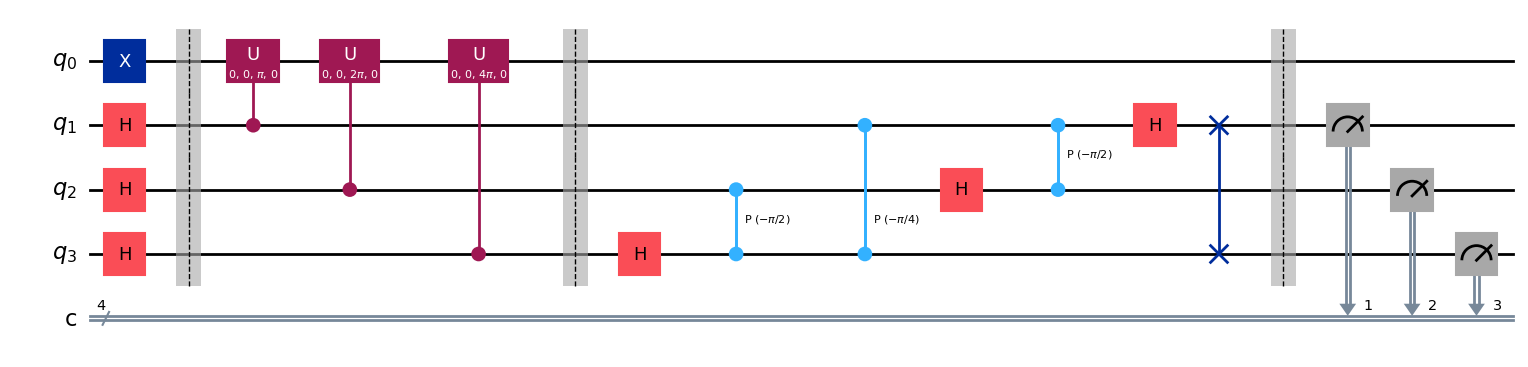

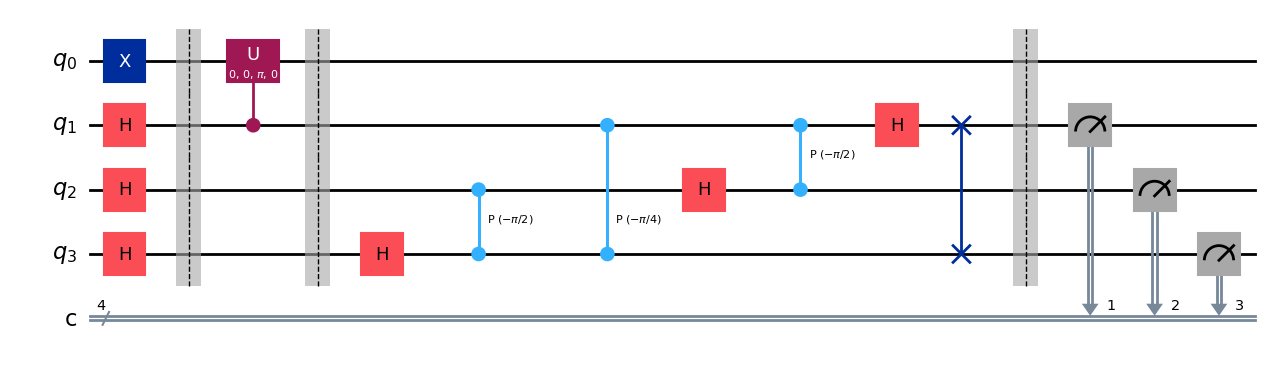

In [7]:
# --- Problem 5: n = 3.  Controlled-U^{2^m}, m = 0, 1, 2:  Z^1 = Z,  Z^2 = I,  Z^{2^{3-1}} = Z^4 = I ---
for m in range(3):
    Zp = np.linalg.matrix_power(Z, 2 ** m)
    CZp = Operator(ZGate().power(2 ** m).control(1)).data
    print(f"m = {m}:  Z^{2 ** m} == I ? {np.allclose(Zp, I2)},   controlled-Z^{2 ** m} == I_4 ? {np.allclose(CZp, np.eye(4))},"
          f"   Z^{2 ** m} == U_(0, 0, {2 ** m}pi) ? {np.allclose(Zp, Operator(UGate(0, 0, 2 ** m * np.pi)).data)}")
full, simple = qpe_circuit(3, "1", simplify=False), qpe_circuit(3, "1", simplify=True)
same = np.allclose(Operator(full.remove_final_measurements(inplace=False)).data,
                   Operator(simple.remove_final_measurements(inplace=False)).data)
print("Full circuit (all three controlled gates) == simplified circuit (only controlled-Z) ?", same)
sv = Statevector(simple.remove_final_measurements(inplace=False))
print("Statevector:", {str(k): round(float(v), 4) for k, v in sv.probabilities_dict().items() if v > 1e-9}, "  (string q3 q2 q1 q0 = c2 c1 c0 b)")
save_circuit(full, "problem-5-circuit-full.png", fold=-1)
save_circuit(simple, "problem-5-circuit.png", fold=-1)


ideal : [('1000', 1024)]
noisy : [('1000', 991), ('0000', 14), ('1010', 10), ('0010', 4)]    ->  P(1000) = 0.968
with the b-register measured too, ideal : {'1001': 1024}


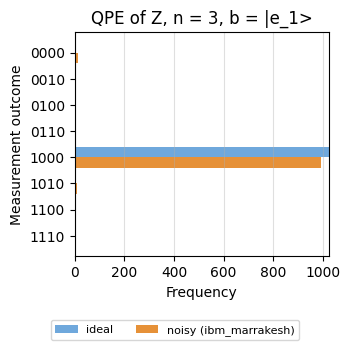

In [8]:
# --- Problem 5: run it (c-register measured into c1..c3; q0 = b is not measured, so its bit stays 0) ---
qc = qpe_circuit(3, "1")
ci, cn = run(qc, ideal), run(qc, noisy)
top = lambda cnt: sorted(cnt.items(), key=lambda kv: -kv[1])[:4]
print("ideal :", top(ci))
print("noisy :", top(cn), f"   ->  P(1000) = {cn.get('1000', 0) / SHOTS:.3f}")
qcb = qpe_circuit(3, "1", measure_b=True)
print("with the b-register measured too, ideal :", run(qcb, ideal))
histograms([("QPE of Z, n = 3, b = |e_1>", ci, cn)], "problem-5-answer.png", 4,
           keys=[format(k, "03b") + "0" for k in range(8)])


---

## **6. Derive the General QPE Algorithm**

In [9]:
# --- Problem 6: general QPE.  After kickback the c-register is (1/sqrt N) sum_j e^{i 2 pi psi j}|j>;
#     U_QFT maps it to sum_k  [ (1/N) sum_j e^{i 2 pi j (psi - k/N)} ] |k>  =  |k>  when  psi = k / N ---
def qpe_probs(n, psi):
    N = 2 ** n
    c = np.exp(2j * np.pi * psi * np.arange(N)) / np.sqrt(N)
    return np.abs(qft_matrix(N) @ c) ** 2


# (a) exact phases psi = k / 2^n: k is read out with probability 1, for every n and every k
for n in range(1, 7):
    N = 2 ** n
    ok = all(np.isclose(qpe_probs(n, k / N)[k], 1) for k in range(N))
    print(f"n = {n}:  psi = k/2^n  ->  P(k) = 1 for all k = 0..{N - 1} ? {ok}")

# (b) the same with a real circuit: U = phase gate P(2 pi psi), controlled-U^{2^m} = cp(2 pi psi 2^m)
def qpe_general(n, psi):
    qc = QuantumCircuit(n + 1)
    qc.x(0)                                        # eigenvector |1> of P(2 pi psi), eigenvalue e^{i 2 pi psi}
    for m in range(n):
        qc.h(m + 1)
        qc.cp(2 * np.pi * psi * 2 ** m, m + 1, 0)
    qc.compose(qft_circuit(n), qubits=list(range(1, n + 1)), inplace=True)
    return qc


for n, k in ((3, 5), (4, 11), (5, 19)):
    probs = Statevector(qpe_general(n, k / 2 ** n)).probabilities_dict()
    best = max(probs, key=probs.get)
    print(f"circuit n = {n}, psi = {k}/{2 ** n}:  most likely string {best} (c = {int(best[:-1], 2)}, b = {best[-1]}),  P = {probs[best]:.4f}")

# (c) psi not a multiple of 1/2^n: the answer is only the closest k / 2^n, with probability >= 4/pi^2
for n in (3, 5, 8):
    N = 2 ** n
    pr = qpe_probs(n, 0.3)
    k = int(np.argmax(pr))
    print(f"psi = 0.3, n = {n}:  most likely k = {k}  ->  k/2^n = {k / N:.5f},  P = {pr[k]:.4f}  (4/pi^2 = {4 / np.pi ** 2:.4f})")


n = 1:  psi = k/2^n  ->  P(k) = 1 for all k = 0..1 ? True
n = 2:  psi = k/2^n  ->  P(k) = 1 for all k = 0..3 ? True
n = 3:  psi = k/2^n  ->  P(k) = 1 for all k = 0..7 ? True
n = 4:  psi = k/2^n  ->  P(k) = 1 for all k = 0..15 ? True
n = 5:  psi = k/2^n  ->  P(k) = 1 for all k = 0..31 ? True


n = 6:  psi = k/2^n  ->  P(k) = 1 for all k = 0..63 ? True
circuit n = 3, psi = 5/8:  most likely string 1011 (c = 5, b = 1),  P = 1.0000
circuit n = 4, psi = 11/16:  most likely string 10111 (c = 11, b = 1),  P = 1.0000
circuit n = 5, psi = 19/32:  most likely string 100111 (c = 19, b = 1),  P = 1.0000
psi = 0.3, n = 3:  most likely k = 2  ->  k/2^n = 0.25000,  P = 0.5775  (4/pi^2 = 0.4053)
psi = 0.3, n = 5:  most likely k = 10  ->  k/2^n = 0.31250,  P = 0.5731  (4/pi^2 = 0.4053)
psi = 0.3, n = 8:  most likely k = 77  ->  k/2^n = 0.30078,  P = 0.8751  (4/pi^2 = 0.4053)


---